# fibonacci_logical_information_leakage

有限1次元Fibonacci-QECCで、消失領域へ**どの論理情報がどれだけ漏れるか**を測る。
主指標は参照qubitとの相互情報量 $I(R:E)$（bit）。$D_Z$ と $D_X$、厳密KL条件、既存のclassical recoverabilityを併記する。

既存 `fibonacci_seed_variation`、`fibonacci_recoverability_kl`、`fibonacci_finite_size_scaling` の続編。
元の関数ファイルを変更せず同梱し、由来とSHA256を `source_manifest.json` に保存した。

**この配布物について**：本番Notebookは入力・validation・benchmarkまで実行済み。本計算は `RUN_FULL_ANALYSIS=True` で実行する。
`fibonacci_logical_information_leakage_example.ipynb` は小規模の実行済み例であり、本番設定の結果ではない。

**実行済みサンプル版**：n=0,1,2,4,6、W=6,20、m=1〜6。exact上限100、sampledは各100試行。n=0は検証・比較用で、原論文の訂正保証の適用外。W>Nの組合せはskipped表に明記する。

## 1–3. 論理状態・参照qubit・decoupling

$O_a$ はinflation後の重複を除いた巡回軌道、$M_a=|O_a|$ とし、
$$|a_L\rangle=M_a^{-1/2}\sum_{x\in O_a}|x\rangle,\qquad
|\Phi\rangle=\frac{|0\rangle_R|0_L\rangle+|1\rangle_R|1_L\rangle}{\sqrt2}.$$
消失領域 $E$ を環境へ渡し、残存領域 $E^c$ をtrace outする。
$$I(R:E)=S(\rho_R)+S(\rho_E)-S(\rho_{RE}),\quad S(\rho)=-\mathrm{Tr}\rho\log_2\rho.$$
直交性を確認した論理basisでは $S_R=1$、$0\le I(R:E)\le2$。
この最大エンタングル入力の $I(R:E)=0$ は、消失チャネルの厳密訂正可能性と同値である。

Q1–Q3はKL・漏洩・消失タイプ、Q4は複数pairの比較、Q5は固定windowでのサイズ比較、Q6は $D_Z,D_X$ とcollisionで調べる。
finite-sizeの有限データだけで無限系の収束を結論しない。

## 4. 手動入力セル

================================
ここはユーザーが手動入力する
================================

seedは既存解析の `000111 / 010101` を初期値にする。**Nは入力しない**。
`LOGICAL_PAIRS=None` のときSEED_0/1を使う。複数pairを比較する場合だけ、
`[{"pair_id":"p1", "seed_0":"...", "seed_1":"..."}, ...]` を指定する。

まずvalidationとbenchmarkを確認できるよう `RUN_FULL_ANALYSIS=False`。
Trueにすれば同じ設定で本計算・全パターンのCSV保存まで行う。
`MAX_MATRIX_DIMENSION` は個々の厳密スペクトル計算のメモリ上限。超過時は近似で置換せず明示的に停止する。

In [1]:
# ==========================================
# ユーザーが手動入力する解析パラメータ
# ==========================================
SEED_0 = "000111"
SEED_1 = "010101"
PAIR_ID = "L06_W03_P0001"
LOGICAL_PAIRS = None
INFLATION_LIST = [0, 1, 2, 4, 6]
ERASURE_DOMAIN_MODE = "window"  # "window" or "full_ring"
WINDOW_SIZE_LIST = [6, 20]
ERASURE_SIZE_LIST = [1, 2, 3, 4, 5, 6]
ERASURE_TYPE_LIST = ["contiguous", "arbitrary"]
MAX_EXACT_PATTERNS = 100
NUM_RANDOM_SAMPLES = 100
RANDOM_SEED = 42
MAX_DENSE_ERASURE_QUBITS = 12
MAX_MATRIX_DIMENSION = 1024
MAX_DETAIL_ROWS = 1000000
EIGENVALUE_TOL = 1e-12
LEAKAGE_TOL = 1e-10
BENCHMARK_PATTERNS = 100
RUN_FULL_ANALYSIS = True
SAVE_RESULTS = True
SAVE_FIGURES = True
OUTPUT_DIR = "example_results"

================================
ここから下は基本的に自動計算
================================

Python 3.10以上。初回のみ、同梱の `requirements.txt` を使って依存パッケージを導入する。
NotebookとPythonファイルは同じフォルダに置く。

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from leakage_analysis import prepare, benchmark, run_analysis
from fibonacci_leakage_core import OrbitPair, analyze_erasure, von_neumann_entropy, mutual_information_reference_erasure
from leakage_validation import run_validation
from leakage_reporting import plot_vs_m, plot_scaling, plot_scatter, plot_distribution, scaling_assessment, final_report
from theory import paper_seed_conditions, L_theory

CONFIG = {k: globals()[k] for k in (
    'SEED_0','SEED_1','PAIR_ID','LOGICAL_PAIRS','INFLATION_LIST',
    'ERASURE_DOMAIN_MODE','WINDOW_SIZE_LIST','ERASURE_SIZE_LIST','ERASURE_TYPE_LIST',
    'MAX_EXACT_PATTERNS','NUM_RANDOM_SAMPLES','RANDOM_SEED',
    'MAX_DENSE_ERASURE_QUBITS','MAX_MATRIX_DIMENSION','MAX_DETAIL_ROWS',
    'EIGENVALUE_TOL','LEAKAGE_TOL','BENCHMARK_PATTERNS','RUN_FULL_ANALYSIS',
    'SAVE_RESULTS','SAVE_FIGURES','OUTPUT_DIR')}
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
prepared = prepare(CONFIG)
if SAVE_RESULTS:
    Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
    (Path(OUTPUT_DIR) / 'notebook_config.json').write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False), encoding='utf-8')

## 5. seed条件の自動確認

同じk0,k1、巡回非同値、ring境界を含む隣接交換条件を確認する。
ここで「隣接交換条件」は、**1回の異なる隣接bit交換で相手の巡回同値類へ移れないこと**。
元の `adjacent_swap_valid` の定義は維持する。
さらに原論文の条件である、交換で自分自身の巡回同値類へ戻らないことも確認し、原論文の条件を満たすpairだけを解析する。

参考：[Li & Boyle, Appendix E](https://arxiv.org/html/2311.13040v2#A5)（原論文）。

In [3]:
display(prepared['seed_checks'])

,pair_id,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,same_composition,cyclic_inequivalent,cross_swap_01,cross_swap_10,self_swap_0,self_swap_1,paper_seed_condition
0,L06_W03_P0001,000111,010101,6,3,3,True,True,True,False,False,False,False,True


## 6–7. inflation・N・cyclic orbit

置換規則は既存と同じ $1\to10,\ 0\to1$。
$F_{a,n}=\mathrm{inflate}(\mathrm{SEED}_a,n)$、$N=|F_{0,n}|$ とする。
同長性、orbitの重複除去、$O_0\cap O_1=\varnothing$ を検証する。
$M_0\ne M_1$ も許容し、それぞれの $\sqrt{M_a}$ で正規化する。

In [4]:
display(prepared['size_table'])

,pair_id,seed_length,k0,k1,adjacent_swap_valid,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,M0,M1
0,L06_W03_P0001,6,3,3,True,000111,010101,0,6,6,2,6,2
1,L06_W03_P0001,6,3,3,True,000111,010101,1,9,9,3,9,3
2,L06_W03_P0001,6,3,3,True,000111,010101,2,15,15,5,15,5
3,L06_W03_P0001,6,3,3,True,000111,010101,4,39,39,13,39,13
4,L06_W03_P0001,6,3,3,True,000111,010101,6,102,102,34,102,34


## 8. 消失パターンの生成

`window` は `start=(N-W)//2` の中央区間内。中央に物理的意味はない。
windowのcontiguousはその区間内に収まる長さmの全区間。
`full_ring` のcontiguousはring境界をまたぐ区間も含む。m=0、m=Nの重複集合は1パターンにする。

arbitraryは組合せ数が上限以内なら全列挙、それ以外は一様な**復元抽出**を行う。重複試行はそのまま数える。
固定W,mでは既存の `random.Random(f"{RANDOM_SEED}:{W}:{m}")` を使い、異なるNやpairで同じ相対パターン列を共有する。
`full_ring` ではNとともに消失domainが変わるため、固定Eのサイズ比較とは呼ばない。

`calculation_mode=exact/sampled` はパターン探索方式、`operator_mode` は行列計算方式。
`sampled` のmaxは観測最大値。stdはパターン間のばらつきで、信頼区間ではない。

In [5]:
display(prepared['skipped'])
print('実行対象の設定数:', len(prepared['jobs']))

実行対象の設定数: 84


,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_size,reason
0,L06_W03_P0001,000111,010101,0,6,20,window,None,W>N
1,L06_W03_P0001,000111,010101,1,9,20,window,None,W>N
2,L06_W03_P0001,000111,010101,2,15,20,window,None,W>N


## 9–10. orbitからreduced operatorとrho_REを構成

$2^N$ statevectorは本解析では作らない。整数bit maskで残存pattern $r=x_{E^c}$ ごとにgroupingする。
$$\rho_E^{(ab)}=\frac{1}{\sqrt{M_aM_b}}\sum_r
\left(\sum_{x\in O_a:x_{E^c}=r}|x_E\rangle\right)
\left(\sum_{y\in O_b:y_{E^c}=r}\langle y_E|\right).$$
$$\rho_{RE}=\frac12\begin{pmatrix}\rho^{(00)}_E&\rho^{(01)}_E\\(\rho^{(01)}_E)^\dagger&\rho^{(11)}_E\end{pmatrix},\qquad
\rho_E=\tfrac12(\rho^{(00)}_E+\rho^{(11)}_E).$$

小さいmではdense行列を使う。大きいmではoccupied basis上のgrouping factor・連結成分・小さいGram行列を使う。
$\rho=VV^\dagger$ と $V^\dagger V$ の非ゼロ固有値は一致するため、巨大な $2^m$ 行列を確保しない。
成分もrankも大きく上限内で厳密計算できない場合は明示的に停止し、未計算をゼロとして扱わない。

## 11–12. entropy・mutual informationと数値診断

`von_neumann_entropy(rho)` はHermitian性・traceを確認して `np.linalg.eigvalsh` を使う。
$-\mathrm{EIGENVALUE\_TOL}<\lambda<0$ の固有値だけをclipする。正の小固有値はentropyへ含める。
許容範囲を超える負値や正規化不良はエラーにする。

`mutual_information_reference_erasure(...)` / `analyze_erasure(...)` は $S_R,S_E,S_{RE},I_{RE}$ などを返す。
MIの丸め前の値と診断値を保存し、わずかな負値は診断後にのみ0に補正する。
`LEAKAGE_TOL` は「numerically zero」の閾値で、KLは元コードの**整数カウントによる厳密判定**。
KL成功なのに閾値以上の漏洩が出れば停止する。一方、KL失敗でも微小漏洩が閾値未満なら数値ゼロとなり得るので、率の一致は確認項目であり強制しない。

## 13–14. basis識別・coherence漏洩

$$D_Z(E)=\tfrac12\|\rho_E^{(00)}-\rho_E^{(11)}\|_1,\qquad
D_X(E)=\|\rho_E^{(01)}\|_1.$$
$D_X$ は**係数1のraw trace norm**で固定し、追加の1/2を掛けない。正規化された直交論理状態では両者とも $0\le D\le1$。
$D_X$ はoff-diagonal channel blockの補助指標で、単独のPauli X測定の識別距離や情報量のbit数とは異なる。
$D_Z,D_X$ を足してMIへ分解することはしない。

分類は `LEAKAGE_TOL` に基づく：

| leakage_failure_type | 条件 |
|---|---|
| Type 0 | I_RE, D_Z, D_Xが全て閾値未満 |
| Type Z | D_Zが閾値以上、D_Xは閾値未満 |
| Type X | D_Zが閾値未満、D_Xは閾値以上 |
| Type ZX | D_Z,D_Xが両方閾値以上 |

独立した閾値が食い違う境界例はdiagnosticとして残し、Type 0へ強制しない。

## 15. 小さい系で明示的statevectorと照合

このvalidationだけは小さいNのstatevectorと通常のpartial traceを使用する。
rho00/11/01、rho_RE、rho_E、rho_R、entropy、MI、D_Z、D_Xを比較する。
Eが空・全消失、M0≠M1、Type Z/X/ZX、large-m表現も確認する。

In [6]:
validation_df = run_validation()
display(validation_df)
assert validation_df['passed'].all()
if SAVE_RESULTS:
    validation_df.to_csv(Path(OUTPUT_DIR) / 'validation.csv', index=False)

,case,N,M0,M1,patterns_checked,max_error_rho00,max_error_rho11,max_error_rho01,max_error_rho_RE,max_error_rho_E,max_error_rho_R,max_error_S_R,max_error_S_E,max_error_S_RE,max_error_I_RE,max_error_D_Z,max_error_D_X,max_dense_grouping_error,passed,operator_mode
0,Fibonacci n=0; unequal M0/M1; all 64 subsets,6,6,2,64,2.220446e-16,2.220446e-16,0.000000e+00,1.110223e-16,5.551115e-17,1.665335e-16,0.0,2.442491e-14,3.974598e-14,3.974598e-14,2.220446e-16,0.000000e+00,5.355153e-14,True,NaN
1,Type 0,2,1,1,1,0.000000e+00,0.000000e+00,0.000000e+00,1.110223e-16,2.220446e-16,1.110223e-16,0.0,3.203427e-16,0.000000e+00,2.220446e-16,0.000000e+00,0.000000e+00,0.000000e+00,True,NaN
2,Type Z,2,1,1,1,0.000000e+00,0.000000e+00,0.000000e+00,1.110223e-16,1.110223e-16,1.110223e-16,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.220446e-16,True,NaN
3,Type X,2,2,2,1,1.110223e-16,1.110223e-16,1.110223e-16,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.220446e-16,0.000000e+00,True,NaN
4,Type ZX / full loss,2,1,1,1,0.000000e+00,0.000000e+00,0.000000e+00,1.110223e-16,1.110223e-16,1.110223e-16,0.0,0.000000e+00,3.203427e-16,2.220446e-16,0.000000e+00,0.000000e+00,2.220446e-16,True,NaN
5,Unequal orbits / empty and full,3,2,3,2,2.220446e-16,2.220446e-16,5.551115e-17,1.110223e-16,5.551115e-17,1.110223e-16,0.0,6.661338e-15,3.775204e-15,2.886580e-15,2.220446e-16,0.000000e+00,3.433115e-15,True,NaN
6,Large m exact grouping: known full-loss endpoint,1000,64,64,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,grouping_components_gram


## 16. 本計算前のbenchmark

100〜1000試行を設定間へ配分して実測する（短いパターン列は繰り返して測定）。
N、m、2^m、試行数、実測時間、1試行時間、全件見積りを確認する。
見積りは観測した処理速度に基づき、collisionやrankによって実行時間は変動する。
m=12でもrho_REだけで8192×8192になり得るため、m閾値だけでなく行列次元の上限も使う。

In [7]:
benchmark_df = benchmark(prepared, CONFIG)
display(benchmark_df)
print('総試行数:', int(prepared['jobs'].number_of_patterns.sum()))
print('本計算の推定合計時間（秒）:', round(float(benchmark_df.estimated_total_seconds.sum()), 2) if not benchmark_df.empty else 0)
if SAVE_RESULTS:
    benchmark_df.to_csv(Path(OUTPUT_DIR) / 'benchmark.csv', index=False)

総試行数: 1670
本計算の推定合計時間（秒）: 0.99


,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,window_start,window_end,calculation_mode,number_of_patterns,total_possible_patterns,hilbert_dimension_E,pattern_count,runtime_seconds,seconds_per_pattern,timing_source,benchmark_safety_factor,config_fingerprint,estimated_total_seconds
0,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,exact,6,6,2,1,0.000259,0.000259,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.002327
1,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,exact,6,6,2,2,0.000311,0.000155,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.001398
2,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,2,0,5,exact,5,5,4,1,0.000151,0.000151,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.001130
3,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,2,0,5,exact,15,15,4,1,0.000149,0.000149,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.003344
4,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,3,0,5,exact,4,4,8,2,0.000326,0.000163,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.000979
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,4,41,60,sampled,100,4845,16,1,0.000362,0.000362,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.054344
80,L06_W03_P0001,000111,010101,6,102,20,window,contiguous,5,41,60,exact,16,16,32,1,0.000436,0.000436,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.010458
81,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,5,41,60,sampled,100,15504,32,1,0.000462,0.000462,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.069300
82,L06_W03_P0001,000111,010101,6,102,20,window,contiguous,6,41,60,exact,15,15,64,2,0.001670,0.000835,measured,1.5,466fa549068d89ae048d5537bb7e74dd13967584cd7166...,0.018785


## 17. 本計算

元の `LogicalPair.evaluate(E)` と新しい漏洩計算のKL・collisionを各パターンで照合する。
原論文の長さ保証やKL成功を理由にMIをゼロと代入せず、実際のreduced operatorから計算する。

In [8]:
results = run_analysis(CONFIG, prepared=prepared) if RUN_FULL_ANALYSIS else None
if results is not None and results['detail'].empty:
    print('計算対象がありません。skipped表とwindow/mの設定を確認してください。')
    results = None
if results is None:
    print('準備・validation・benchmark完了。結果がない場合は対象設定とRUN_FULL_ANALYSISを確認してください。')
else:
    print(f"計算完了: {len(results['detail']):,}試行")

計算完了: 1,670試行


## 18–19. detail・summary DataFrame

各消失試行をdetailの1行へ保存する。同じ相対patternでもNや消失typeが違えば別行。
summaryにはmean/median/std/min/max/quantile、D_Z/D_X、decoupled/KL/recoverability率を保存する。
worst表は各設定内の観測最大pattern。相対位置と絶対位置はCSV内でJSON配列として保存する。

In [9]:
if results is not None:
    detail_df, summary_df = results['detail'], results['summary']
    display(detail_df.head(20))
    display(summary_df)

,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,window_start,window_end,seed_length,k0,k1,adjacent_swap_valid,...,rho_RE_trace,rho_E_min_eigenvalue,rho_RE_min_eigenvalue,KL_MI_consistent,erasure_positions_relative,erasure_positions_absolute,pattern_id,pattern_index,operator_mode,random_seed,important_case,contiguous_runs_ring,max_cyclic_gap,legacy_core_agree,KL_implies_decoupling_verified
0,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(0,)","(0,)",c8f51f30ba54bb8483cea645,0,dense_erasure,42,B,1,5,True,True
1,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(1,)","(1,)",3449a07c44258b53419ff939,1,dense_erasure,42,B,1,5,True,True
2,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(2,)","(2,)",cf08f6e04434cc99f66f05ce,2,dense_erasure,42,B,1,5,True,True
3,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(3,)","(3,)",a8a00745e28de4ca7fa2ca67,3,dense_erasure,42,B,1,5,True,True
4,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(4,)","(4,)",93eca699bbb68f741b5095d0,4,dense_erasure,42,B,1,5,True,True
5,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(5,)","(5,)",930425c81b39b06572140302,5,dense_erasure,42,B,1,5,True,True
6,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(0,)","(0,)",06a02394a306369b13feec1b,0,dense_erasure,42,B,1,5,True,True
7,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(1,)","(1,)",4b33d759142be8306bf48c3b,1,dense_erasure,42,B,1,5,True,True
8,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(2,)","(2,)",968c402ac1bb902236b9488a,2,dense_erasure,42,B,1,5,True,True
9,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,1.0,0.0,0.000000e+00,True,"(3,)","(3,)",c75a6a0164cb9ee5e21fc6e1,3,dense_erasure,42,B,1,5,True,True


,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,mean_I_RE,median_I_RE,std_I_RE,min_I_RE,max_I_RE,mean_D_Z,...,decoupled_rate,KL_success_rate,recoverability_success_rate,recoverable_with_leakage_rate,number_of_patterns,number_of_unique_patterns,calculation_mode,operator_modes,maximum_interpretation,KL_decoupling_rate_difference,KL_decoupling_numerical_mismatch_count,q05_I_RE,q25_I_RE,q75_I_RE,q95_I_RE
0,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,...,1.0,1.0,1.0,0.0,6,6,exact,dense_erasure,exact_maximum,0.0,0,0.000000,0.000000,0.000000,0.000000e+00
1,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,...,1.0,1.0,1.0,0.0,6,6,exact,dense_erasure,exact_maximum,0.0,0,0.000000,0.000000,0.000000,0.000000e+00
2,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,2,4.591479e-01,0.459148,0.000000e+00,0.459148,4.591479e-01,0.666667,...,0.0,0.0,1.0,1.0,5,5,exact,dense_erasure,exact_maximum,0.0,0,0.459148,0.459148,0.459148,4.591479e-01
3,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,2,4.591479e-01,0.459148,2.775558e-16,0.459148,4.591479e-01,0.600000,...,0.0,0.0,0.8,0.8,15,15,exact,dense_erasure,exact_maximum,0.0,0,0.459148,0.459148,0.459148,4.591479e-01
4,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,3,1.000000e+00,1.000000,0.000000e+00,1.000000,1.000000e+00,1.000000,...,0.0,0.0,1.0,1.0,4,4,exact,dense_erasure,exact_maximum,0.0,0,1.000000,1.000000,1.000000,1.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,4,5.773160e-17,0.000000,1.620165e-16,0.000000,8.881784e-16,0.000000,...,1.0,1.0,1.0,0.0,100,98,sampled,dense_erasure,observed_sample_maximum,0.0,0,0.000000,0.000000,0.000000,4.440892e-16
80,L06_W03_P0001,000111,010101,6,102,20,window,contiguous,5,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,...,1.0,1.0,1.0,0.0,16,16,exact,dense_erasure,exact_maximum,0.0,0,0.000000,0.000000,0.000000,0.000000e+00
81,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,5,6.217249e-17,0.000000,1.778576e-16,0.000000,8.881784e-16,0.000000,...,1.0,1.0,1.0,0.0,100,100,sampled,dense_erasure,observed_sample_maximum,0.0,0,0.000000,0.000000,0.000000,4.440892e-16
82,L06_W03_P0001,000111,010101,6,102,20,window,contiguous,6,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,...,1.0,1.0,1.0,0.0,15,15,exact,dense_erasure,exact_maximum,0.0,0,0.000000,0.000000,0.000000,0.000000e+00


## 20. I_RE vs m・worst-case leakage

error barは標準偏差。sampledのmaxは観測最大、exactのmaxは指定したdomainとmの全探索最大。

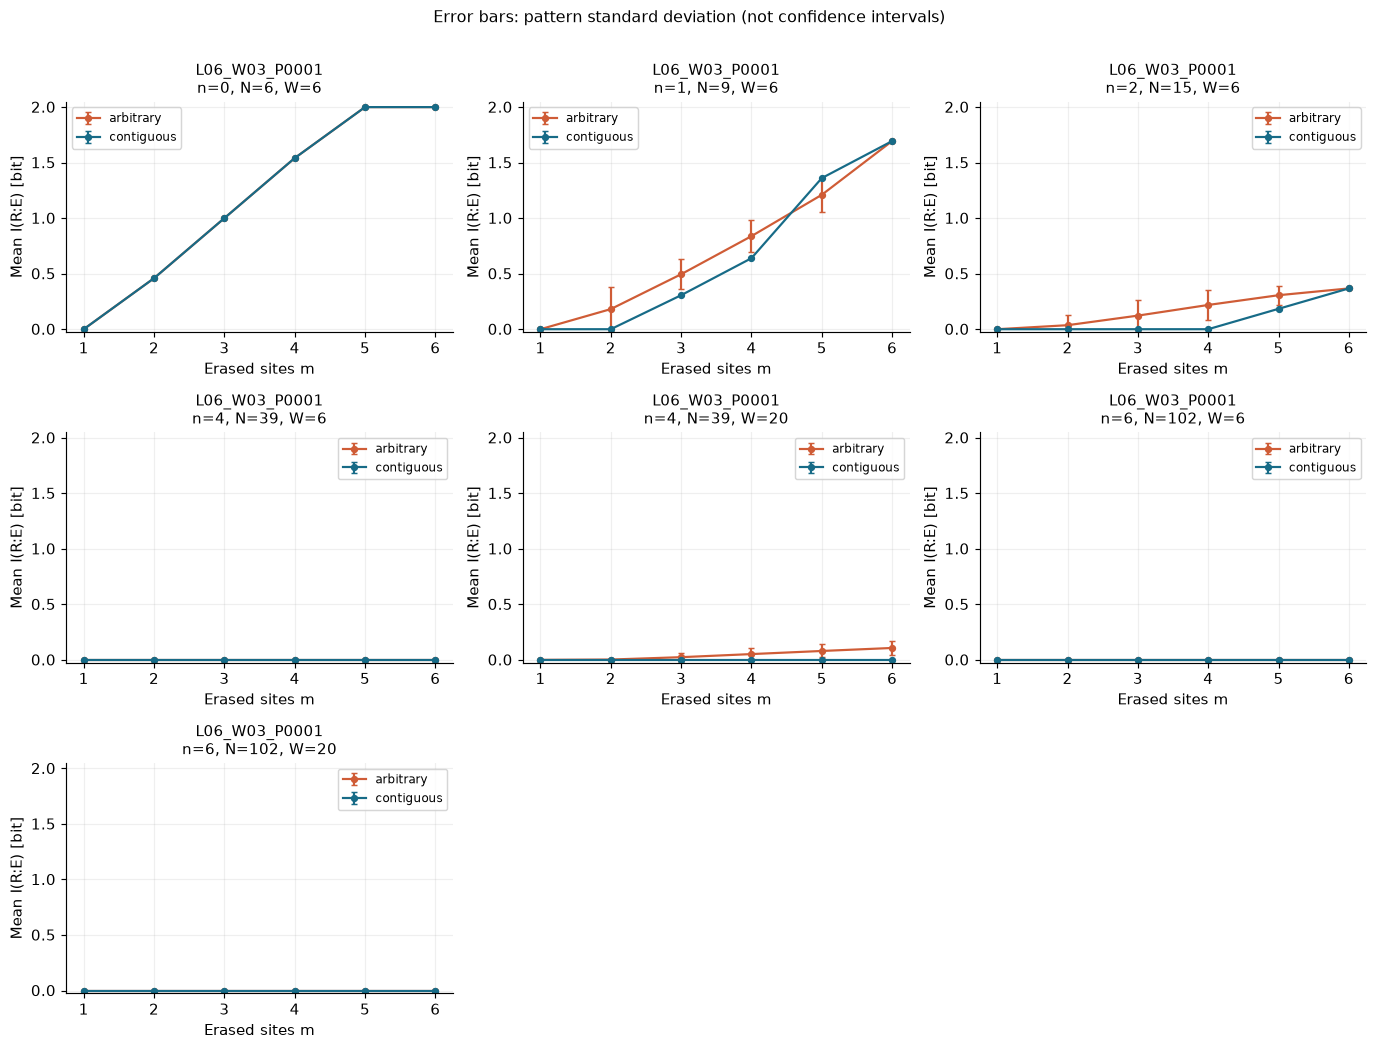

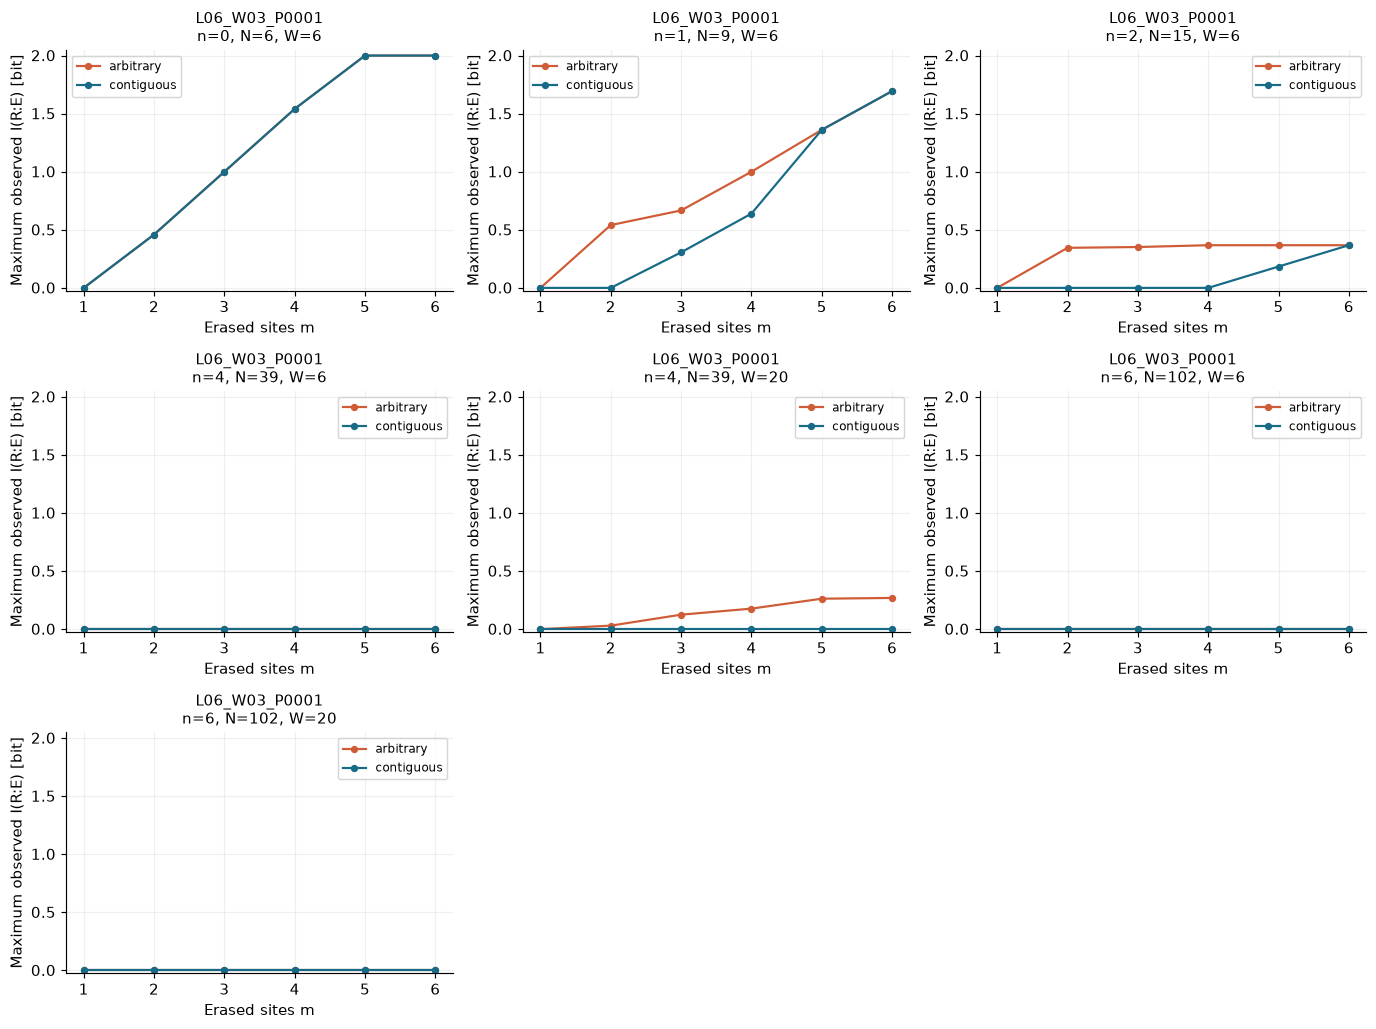

In [10]:
if results is not None:
    for metric in ('mean_I_RE', 'max_I_RE'):
        fig = plot_vs_m(summary_df, metric, OUTPUT_DIR, SAVE_FIGURES)
        display(fig); plt.close(fig)

## 21. D_Z / D_X と漏洩分布

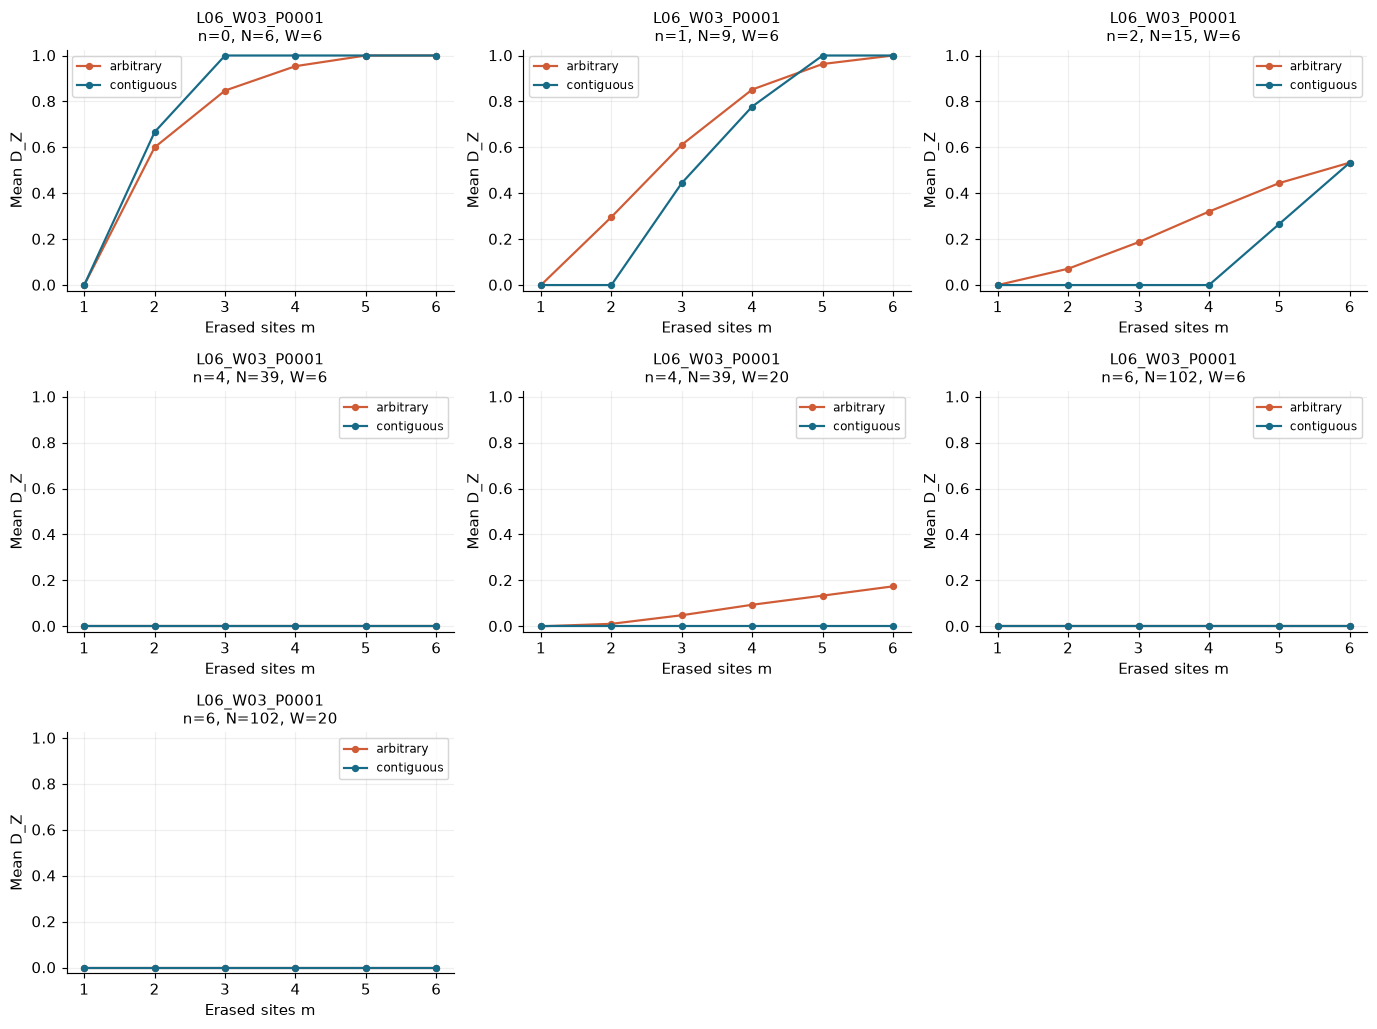

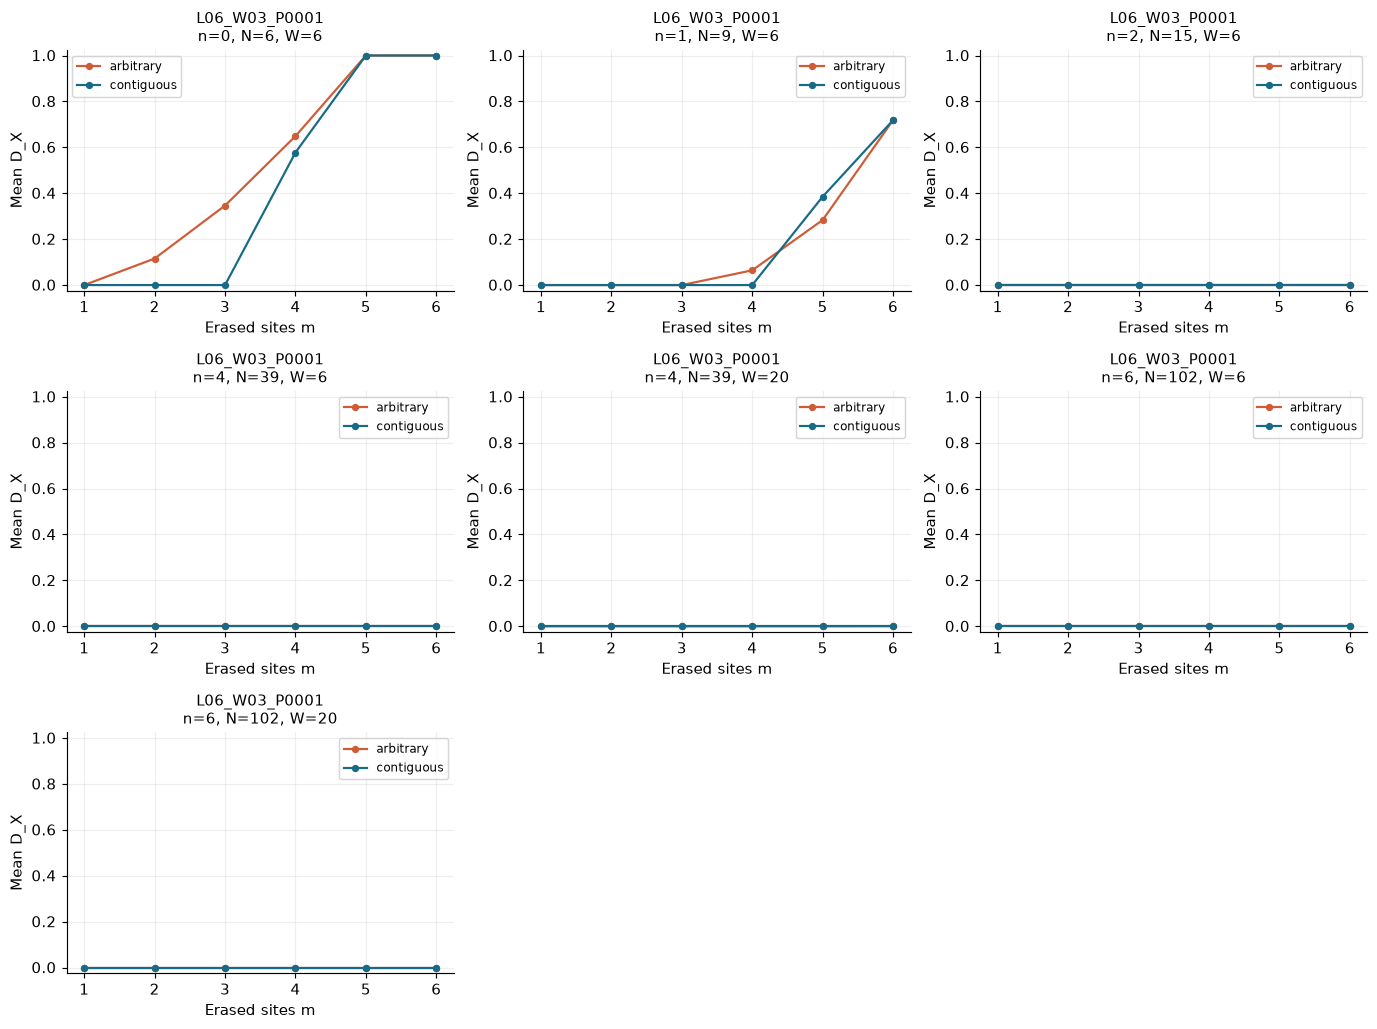

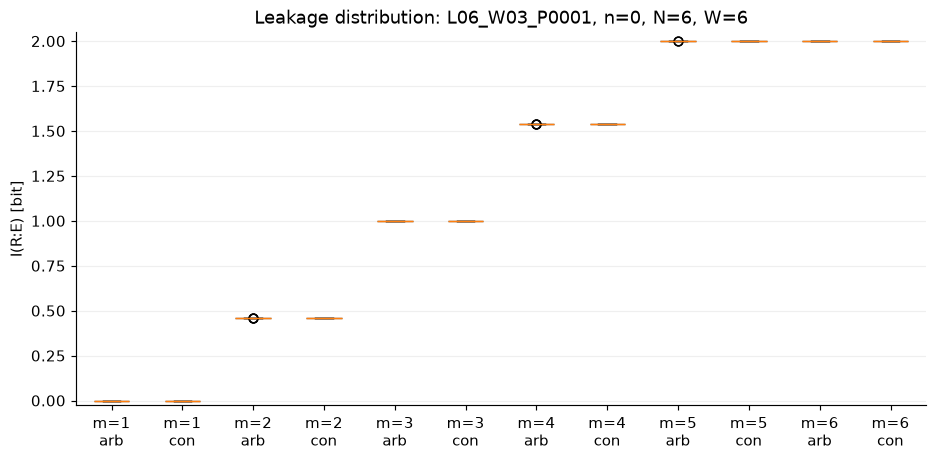

In [11]:
if results is not None:
    for metric in ('mean_D_Z', 'mean_D_X'):
        fig = plot_vs_m(summary_df, metric, OUTPUT_DIR, SAVE_FIGURES)
        display(fig); plt.close(fig)
    fig = plot_distribution(detail_df, OUTPUT_DIR, SAVE_FIGURES)
    display(fig); plt.close(fig)

## 22. contiguousとarbitraryの比較

pair,n,N,W,mを固定した比較表。arbitraryにはcontiguous集合も含む。
両者の平均を、それぞれの集合・サンプリング方式の平均として解釈する。

In [12]:
if results is not None:
    display(results['comparisons'])

,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_size,mean_I_RE_contiguous,max_I_RE_contiguous,mean_D_Z_contiguous,mean_D_X_contiguous,KL_success_rate_contiguous,recoverability_success_rate_contiguous,calculation_mode_contiguous,number_of_patterns_contiguous,mean_I_RE_arbitrary,max_I_RE_arbitrary,mean_D_Z_arbitrary,mean_D_X_arbitrary,KL_success_rate_arbitrary,recoverability_success_rate_arbitrary,calculation_mode_arbitrary,number_of_patterns_arbitrary,arbitrary_minus_contiguous_mean_I_RE
0,L06_W03_P0001,000111,010101,0,6,6,window,1,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,1.0,exact,6,0.000000e+00,0.000000e+00,0.000000,0.000000,1.000000,1.0,exact,6,0.000000e+00
1,L06_W03_P0001,000111,010101,0,6,6,window,2,4.591479e-01,4.591479e-01,0.666667,0.000000,0.0,1.0,exact,5,4.591479e-01,4.591479e-01,0.600000,0.115470,0.000000,0.8,exact,15,-5.551115e-17
2,L06_W03_P0001,000111,010101,0,6,6,window,3,1.000000e+00,1.000000e+00,1.000000,0.000000,0.0,1.0,exact,4,1.000000e+00,1.000000e+00,0.847214,0.346410,0.000000,0.4,exact,20,-3.330669e-16
3,L06_W03_P0001,000111,010101,0,6,6,window,4,1.540852e+00,1.540852e+00,1.000000,0.577350,0.0,0.0,exact,3,1.540852e+00,1.540852e+00,0.953518,0.648715,0.000000,0.0,exact,15,-6.661338e-16
4,L06_W03_P0001,000111,010101,0,6,6,window,5,2.000000e+00,2.000000e+00,1.000000,1.000000,0.0,0.0,exact,2,2.000000e+00,2.000000e+00,1.000000,1.000000,0.000000,0.0,exact,6,-4.218847e-15
5,L06_W03_P0001,000111,010101,0,6,6,window,6,2.000000e+00,2.000000e+00,1.000000,1.000000,0.0,0.0,exact,1,2.000000e+00,2.000000e+00,1.000000,1.000000,0.000000,0.0,exact,1,0.000000e+00
6,L06_W03_P0001,000111,010101,1,9,6,window,1,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,1.0,exact,6,0.000000e+00,0.000000e+00,0.000000,0.000000,1.000000,1.0,exact,6,0.000000e+00
7,L06_W03_P0001,000111,010101,1,9,6,window,2,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,1.0,exact,5,1.810552e-01,5.408521e-01,0.296296,0.000000,0.333333,0.8,exact,15,1.810552e-01
8,L06_W03_P0001,000111,010101,1,9,6,window,3,3.060986e-01,3.060986e-01,0.444444,0.000000,0.0,1.0,exact,4,4.948632e-01,6.666667e-01,0.611111,0.000000,0.000000,0.4,exact,20,1.887646e-01
9,L06_W03_P0001,000111,010101,1,9,6,window,4,6.394319e-01,6.394319e-01,0.777778,0.000000,0.0,0.0,exact,3,8.378879e-01,1.000000e+00,0.851852,0.064150,0.000000,0.0,exact,15,1.984559e-01


## 23. KL・recoverability・collisionとの比較

既存 `recoverable_both` は**各orbit内**の残存patternへの写像が単射という意味であり、論理0/1間のcross collisionは除外しない。
self collision countは順序なしの異なる組、cross countはO0×O1の組。

`comparison_type` の既存定義は A=rec成功/KL成功、B=rec成功/KL失敗、C=rec失敗/KL成功、D=両方失敗。
今回の重要ケースは**別の列**で示す：Case A=rec成功/KL失敗/漏洩あり、Case B=rec成功/KL成功/数値ゼロ、Case C=rec失敗/KL成功。
Case Dは同じ設定内の最大漏洩patternをworst表へ保存する。「極端」の普遍的な閾値は仮定しない。
正の等振幅なのでcross collisionの存在とoff-diagonal operator非ゼロは同値だが、個数だけで漏洩の大きさは決まらない。

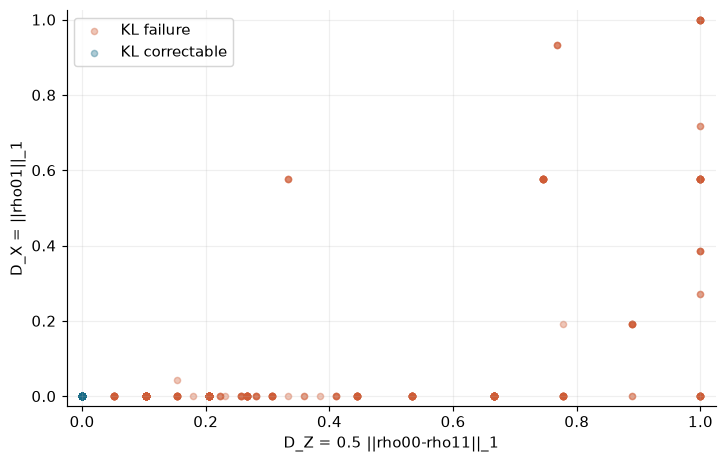

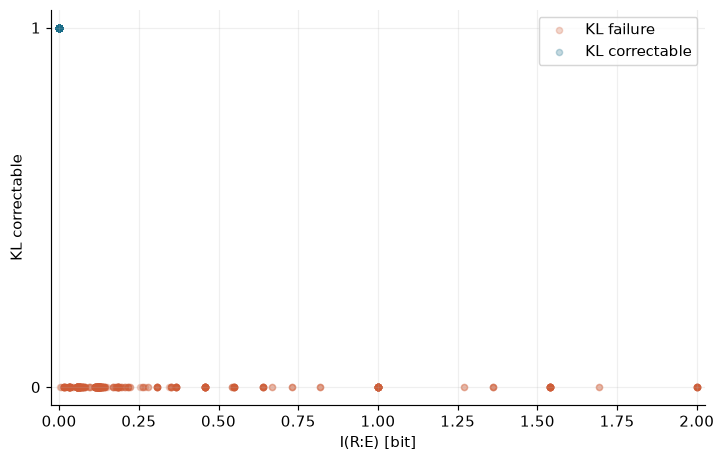

,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,window_start,window_end,seed_length,k0,k1,adjacent_swap_valid,...,random_seed,important_case,contiguous_runs_ring,max_cyclic_gap,legacy_core_agree,KL_implies_decoupling_verified,max_I_RE,maximum_interpretation,is_exact_numeric_maximum,distance_below_numeric_maximum,worst_erasure_positions,tied_maximum_draws,repeated_draw_count,important_case_D,important_case_definition
0,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,42,B,1,5,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,collision_field,collision_present,number_of_patterns,mean_I_RE,mean_D_Z,mean_D_X,note
0,cross_collision,False,1611,0.049063,0.069720,0.000000,pooled_descriptive_summary; inspect fixed pair...
1,cross_collision,True,59,1.345676,0.873085,0.593813,pooled_descriptive_summary; inspect fixed pair...
2,self_collision_0,False,1582,0.038101,0.057288,0.000028,pooled_descriptive_summary; inspect fixed pair...
3,self_collision_0,True,88,1.115449,0.831848,0.397620,pooled_descriptive_summary; inspect fixed pair...
4,self_collision_1,False,1668,0.092587,0.097021,0.019805,pooled_descriptive_summary; inspect fixed pair...
5,self_collision_1,True,2,2.000000,1.000000,1.000000,pooled_descriptive_summary; inspect fixed pair...


,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,mean_I_RE,median_I_RE,std_I_RE,min_I_RE,max_I_RE,mean_D_Z,...,recoverability_success_rate,recoverable_with_leakage_rate,number_of_patterns,number_of_unique_patterns,calculation_mode,operator_modes,maximum_interpretation,KL_decoupling_rate_difference,KL_decoupling_numerical_mismatch_count,q05_I_RE,q25_I_RE,q75_I_RE,q95_I_RE,KL_failure_rate,recoverability_failure_rate
1,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,...,1.0,0.000000,6,6,exact,dense_erasure,exact_maximum,0.0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
3,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,2,4.591479e-01,4.591479e-01,2.775558e-16,4.591479e-01,4.591479e-01,0.600000,...,0.8,0.800000,15,15,exact,dense_erasure,exact_maximum,0.0,0,4.591479e-01,4.591479e-01,4.591479e-01,4.591479e-01,1.000000,0.2
5,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,3,1.000000e+00,1.000000e+00,7.004091e-16,1.000000e+00,1.000000e+00,0.847214,...,0.4,0.400000,20,20,exact,dense_erasure,exact_maximum,0.0,0,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000,0.6
7,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,4,1.540852e+00,1.540852e+00,1.064889e-15,1.540852e+00,1.540852e+00,0.953518,...,0.0,0.000000,15,15,exact,dense_erasure,exact_maximum,0.0,0,1.540852e+00,1.540852e+00,1.540852e+00,1.540852e+00,1.000000,1.0
9,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,5,2.000000e+00,2.000000e+00,9.965656e-15,2.000000e+00,2.000000e+00,1.000000,...,0.0,0.000000,6,6,exact,dense_erasure,exact_maximum,0.0,0,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,1.000000,1.0
11,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,6,2.000000e+00,2.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,1.000000,...,0.0,0.000000,1,1,exact,dense_erasure,exact_maximum,0.0,0,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,1.000000,1.0
13,L06_W03_P0001,000111,010101,1,9,6,window,arbitrary,1,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,...,1.0,0.000000,6,6,exact,dense_erasure,exact_maximum,0.0,0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
15,L06_W03_P0001,000111,010101,1,9,6,window,arbitrary,2,1.810552e-01,7.743873e-02,1.981833e-01,0.000000e+00,5.408521e-01,0.296296,...,0.8,0.466667,15,15,exact,dense_erasure,exact_maximum,0.0,0,0.000000e+00,0.000000e+00,2.152391e-01,5.408521e-01,0.666667,0.2
17,L06_W03_P0001,000111,010101,1,9,6,window,arbitrary,3,4.948632e-01,5.500075e-01,1.352490e-01,2.802990e-01,6.666667e-01,0.611111,...,0.4,0.400000,20,20,exact,dense_erasure,exact_maximum,0.0,0,2.802990e-01,3.060986e-01,5.500075e-01,6.666667e-01,1.000000,0.6
19,L06_W03_P0001,000111,010101,1,9,6,window,arbitrary,4,8.378879e-01,8.197160e-01,1.441198e-01,6.394319e-01,1.000000e+00,0.851852,...,0.0,0.000000,15,15,exact,dense_erasure,exact_maximum,0.0,0,6.394319e-01,7.302915e-01,1.000000e+00,1.000000e+00,1.000000,1.0


,inflation_n,N,window_size,erasure_domain_mode,erasure_size,failure_metric,number_of_distinct_pairs,pearson_r,status,interpretation
0,0,6,6,window,1,KL_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
1,0,6,6,window,1,recoverability_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
2,0,6,6,window,2,KL_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
3,0,6,6,window,2,recoverability_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
4,0,6,6,window,3,KL_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
...,...,...,...,...,...,...,...,...,...,...
79,6,102,20,window,4,recoverability_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
80,6,102,20,window,5,KL_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
81,6,102,20,window,5,recoverability_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim
82,6,102,20,window,6,KL_failure_rate,1,NaN,requires_at_least_3_distinct_pairs,descriptive_only_no_causal_or_asymptotic_claim


In [13]:
if results is not None:
    for kind in ('DZ_DX', 'I_RE_KL'):
        fig = plot_scatter(detail_df, kind, OUTPUT_DIR, SAVE_FIGURES)
        display(fig); plt.close(fig)
    display(results['cases'].head(30))
    display(results['collisions'])
    display(results['pair_strength'])
    display(results['pair_correlations'])

## 24. fixed-window finite-size scaling

固定 $W,m,E_{relative}$ でNを変える。finite_size表のpattern IDとdigestで対応を確認する。
平均曲線に加え、同じ試行の隣接サイズ間変化を保存する。
Q4のpair間傾向は複数pair・変動がある場合のみ記述的な相関を計算する。

[原論文 Appendix E](https://arxiv.org/html/2311.13040v2#A5)の条件を満たすpairでは、$n\ge1$、$f_0=f_1=1$、連続領域長 $L(n)=f_n+1$ が保証される。
固定window $W\le L(n)$ に含まれる任意の消失集合も訂正可能である（保証領域の部分消失への適用）。
保証の外側は「訂正不能」とは判定しない。full_ringの任意消失にはwindowの保証をそのまま使わない。

,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,window_start,window_end,seed_length,k0,k1,adjacent_swap_valid,...,important_case,contiguous_runs_ring,max_cyclic_gap,legacy_core_agree,KL_implies_decoupling_verified,fixed_relative_pattern_comparison,finite_size_interpretation,previous_N,previous_I_RE,previous_D_Z,previous_D_X,delta_I_RE,delta_D_Z,delta_D_X,same_relative_pattern_verified
0,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,B,1,5,True,True,True,fixed_W_m_relative_pattern,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,L06_W03_P0001,000111,010101,1,9,6,window,arbitrary,1,1,6,6,3,3,True,...,B,1,8,True,True,True,fixed_W_m_relative_pattern,6.0,0.0,0.0,0.0,0.0,0.0,0.0,True
2,L06_W03_P0001,000111,010101,2,15,6,window,arbitrary,1,4,9,6,3,3,True,...,B,1,14,True,True,True,fixed_W_m_relative_pattern,9.0,0.0,0.0,0.0,0.0,0.0,0.0,True
3,L06_W03_P0001,000111,010101,4,39,6,window,arbitrary,1,16,21,6,3,3,True,...,B,1,38,True,True,True,fixed_W_m_relative_pattern,15.0,0.0,0.0,0.0,0.0,0.0,0.0,True
4,L06_W03_P0001,000111,010101,6,102,6,window,arbitrary,1,48,53,6,3,3,True,...,B,1,101,True,True,True,fixed_W_m_relative_pattern,39.0,0.0,0.0,0.0,0.0,0.0,0.0,True
5,L06_W03_P0001,000111,010101,0,6,6,window,arbitrary,1,0,5,6,3,3,True,...,B,1,5,True,True,True,fixed_W_m_relative_pattern,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
6,L06_W03_P0001,000111,010101,1,9,6,window,arbitrary,1,1,6,6,3,3,True,...,B,1,8,True,True,True,fixed_W_m_relative_pattern,6.0,0.0,0.0,0.0,0.0,0.0,0.0,True
7,L06_W03_P0001,000111,010101,2,15,6,window,arbitrary,1,4,9,6,3,3,True,...,B,1,14,True,True,True,fixed_W_m_relative_pattern,9.0,0.0,0.0,0.0,0.0,0.0,0.0,True
8,L06_W03_P0001,000111,010101,4,39,6,window,arbitrary,1,16,21,6,3,3,True,...,B,1,38,True,True,True,fixed_W_m_relative_pattern,15.0,0.0,0.0,0.0,0.0,0.0,0.0,True
9,L06_W03_P0001,000111,010101,6,102,6,window,arbitrary,1,48,53,6,3,3,True,...,B,1,101,True,True,True,fixed_W_m_relative_pattern,39.0,0.0,0.0,0.0,0.0,0.0,0.0,True


,pair_id,window_size,erasure_size,erasure_type,number_of_sizes,first_N,last_N,first_mean_I_RE,last_mean_I_RE,observed_nonincreasing,endpoint_decreased,largest_size_all_observed_decoupled,interpretation
0,L06_W03_P0001,6,1,arbitrary,5,6,102,0.000000e+00,0.000000e+00,True,False,True,finite observations; no extrapolation or infin...
1,L06_W03_P0001,6,1,contiguous,5,6,102,0.000000e+00,0.000000e+00,True,False,True,finite observations; no extrapolation or infin...
2,L06_W03_P0001,6,2,arbitrary,5,6,102,4.591479e-01,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
3,L06_W03_P0001,6,2,contiguous,5,6,102,4.591479e-01,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
4,L06_W03_P0001,6,3,arbitrary,5,6,102,1.000000e+00,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
5,L06_W03_P0001,6,3,contiguous,5,6,102,1.000000e+00,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
6,L06_W03_P0001,6,4,arbitrary,5,6,102,1.540852e+00,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
7,L06_W03_P0001,6,4,contiguous,5,6,102,1.540852e+00,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
8,L06_W03_P0001,6,5,arbitrary,5,6,102,2.000000e+00,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...
9,L06_W03_P0001,6,5,contiguous,5,6,102,2.000000e+00,0.000000e+00,True,True,True,finite observations; no extrapolation or infin...


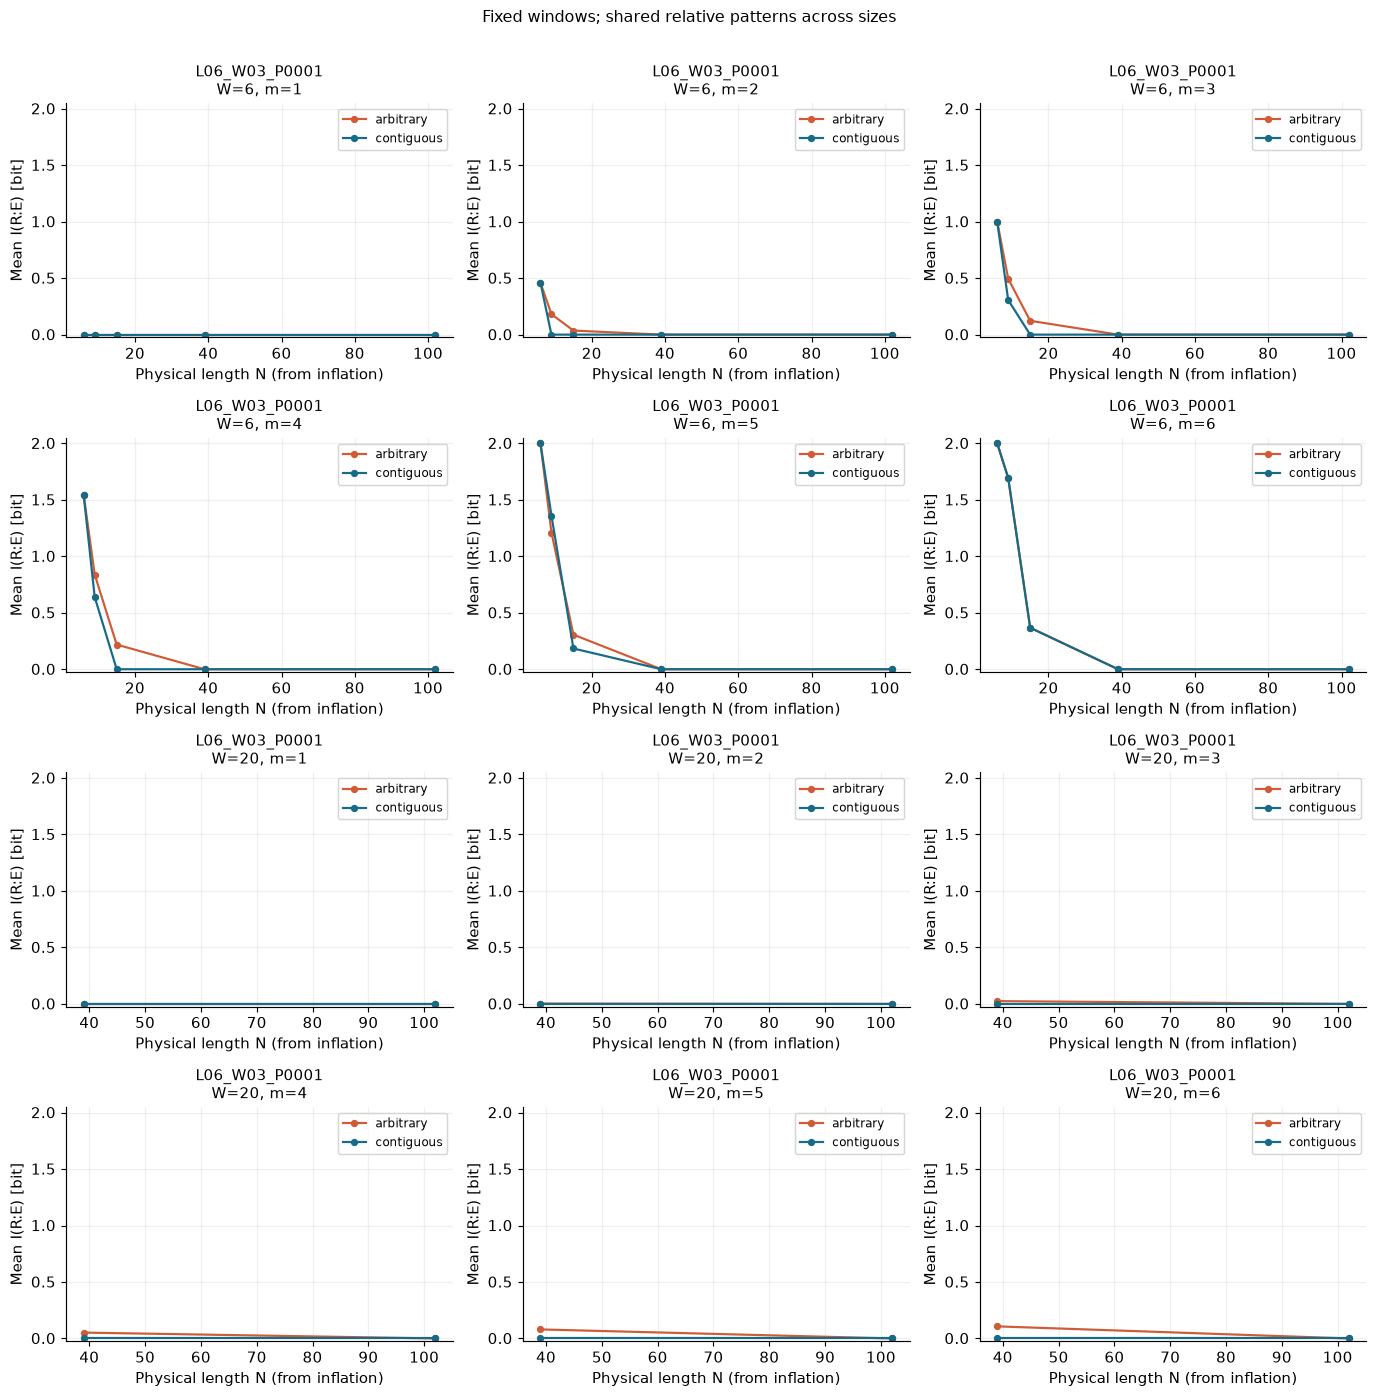

In [14]:
if results is not None:
    display(results['finite_size'].head(30))
    assessment_df = scaling_assessment(summary_df, LEAKAGE_TOL)
    display(assessment_df)
    fig = plot_scaling(summary_df, OUTPUT_DIR, SAVE_FIGURES)
    if fig is not None:
        display(fig); plt.close(fig)
    if SAVE_RESULTS:
        assessment_df.to_csv(Path(OUTPUT_DIR)/'scaling_assessment.csv', index=False)

## 25. worst pattern解析

erasure geometry、KL、recoverability、collision、I_RE/D_Z/D_Xを同じ行で確認する。
最大値との差がLEAKAGE_TOL以下の異なるpatternを同率最大として保存する。各行のI_REと真の数値最大max_I_REを区別する。sampledでは未観測のさらに悪いpatternを否定できない。

In [15]:
if results is not None:
    display(results['worst'])

,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_type,erasure_size,window_start,window_end,seed_length,k0,k1,adjacent_swap_valid,...,operator_mode,random_seed,important_case,contiguous_runs_ring,max_cyclic_gap,legacy_core_agree,KL_implies_decoupling_verified,max_I_RE,maximum_interpretation,is_exact_numeric_maximum,distance_below_numeric_maximum,worst_erasure_positions,tied_maximum_draws,repeated_draw_count,important_case_D
0,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,dense_erasure,42,B,1,5,True,True,0.000000e+00,exact_maximum,True,0.000000e+00,"(0,)",6,1,False
1,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,dense_erasure,42,B,1,5,True,True,0.000000e+00,exact_maximum,True,0.000000e+00,"(1,)",6,1,False
2,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,dense_erasure,42,B,1,5,True,True,0.000000e+00,exact_maximum,True,0.000000e+00,"(2,)",6,1,False
3,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,dense_erasure,42,B,1,5,True,True,0.000000e+00,exact_maximum,True,0.000000e+00,"(3,)",6,1,False
4,L06_W03_P0001,000111,010101,0,6,6,window,contiguous,1,0,5,6,3,3,True,...,dense_erasure,42,B,1,5,True,True,0.000000e+00,exact_maximum,True,0.000000e+00,"(4,)",6,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1069,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,6,41,60,6,3,3,True,...,dense_erasure,42,B,4,91,True,True,8.881784e-16,observed_sample_maximum,False,8.881784e-16,"(49, 50, 51, 53, 55, 59)",100,1,False
1070,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,6,41,60,6,3,3,True,...,dense_erasure,42,B,5,82,True,True,8.881784e-16,observed_sample_maximum,False,8.881784e-16,"(41, 43, 44, 52, 55, 60)",100,1,False
1071,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,6,41,60,6,3,3,True,...,dense_erasure,42,B,6,85,True,True,8.881784e-16,observed_sample_maximum,False,8.881784e-16,"(42, 46, 48, 53, 55, 58)",100,1,False
1072,L06_W03_P0001,000111,010101,6,102,20,window,arbitrary,6,41,60,6,3,3,True,...,dense_erasure,42,B,5,86,True,True,8.881784e-16,observed_sample_maximum,False,8.881784e-16,"(44, 50, 53, 55, 56, 59)",100,1,False


## 26. 結果まとめ

使用pair・隣接交換条件・n/N、各mのKL率、mean/max I_RE、mean D_Z/D_X、
recoverability成功でも漏洩する割合、消失type比較、worst pattern、有限Nの変化を表示する。
有限データから収束やpairの優劣を一般化しない。

Q4は1pairだけでは答えられない。必要なときは手動入力セルで複数pairを指定する。

In [16]:
if results is not None:
    display(prepared['seed_checks'])
    display(prepared['size_table'])
    columns = ['pair_id','inflation_n','N','window_size','erasure_type','erasure_size',
               'KL_success_rate','mean_I_RE','max_I_RE','mean_D_Z','mean_D_X',
               'recoverability_success_rate','recoverable_with_leakage_rate','decoupled_rate','number_of_patterns','calculation_mode']
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(summary_df[columns])
    display(results['comparisons'])
    report = final_report(results, prepared['seed_checks'], LEAKAGE_TOL)
    display(Markdown(report))
    if SAVE_RESULTS:
        (Path(OUTPUT_DIR)/'conclusions.md').write_text(report, encoding='utf-8')
else:
    display(Markdown('本計算の結果はありません。上のvalidation・benchmark・skipped表を確認し、手動入力セルを設定してください。実行結果の例は同梱のexample Notebookにあります。'))

,pair_id,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,same_composition,cyclic_inequivalent,cross_swap_01,cross_swap_10,self_swap_0,self_swap_1,paper_seed_condition
0,L06_W03_P0001,000111,010101,6,3,3,True,True,True,False,False,False,False,True


,pair_id,seed_length,k0,k1,adjacent_swap_valid,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,M0,M1
0,L06_W03_P0001,6,3,3,True,000111,010101,0,6,6,2,6,2
1,L06_W03_P0001,6,3,3,True,000111,010101,1,9,9,3,9,3
2,L06_W03_P0001,6,3,3,True,000111,010101,2,15,15,5,15,5
3,L06_W03_P0001,6,3,3,True,000111,010101,4,39,39,13,39,13
4,L06_W03_P0001,6,3,3,True,000111,010101,6,102,102,34,102,34


,pair_id,inflation_n,N,window_size,erasure_type,erasure_size,KL_success_rate,mean_I_RE,max_I_RE,mean_D_Z,mean_D_X,recoverability_success_rate,recoverable_with_leakage_rate,decoupled_rate,number_of_patterns,calculation_mode
0,L06_W03_P0001,0,6,6,contiguous,1,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,0.000000,1.000000,6,exact
1,L06_W03_P0001,0,6,6,arbitrary,1,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,0.000000,1.000000,6,exact
2,L06_W03_P0001,0,6,6,contiguous,2,0.000000,4.591479e-01,4.591479e-01,0.666667,0.000000,1.0,1.000000,0.000000,5,exact
3,L06_W03_P0001,0,6,6,arbitrary,2,0.000000,4.591479e-01,4.591479e-01,0.600000,0.115470,0.8,0.800000,0.000000,15,exact
4,L06_W03_P0001,0,6,6,contiguous,3,0.000000,1.000000e+00,1.000000e+00,1.000000,0.000000,1.0,1.000000,0.000000,4,exact
5,L06_W03_P0001,0,6,6,arbitrary,3,0.000000,1.000000e+00,1.000000e+00,0.847214,0.346410,0.4,0.400000,0.000000,20,exact
6,L06_W03_P0001,0,6,6,contiguous,4,0.000000,1.540852e+00,1.540852e+00,1.000000,0.577350,0.0,0.000000,0.000000,3,exact
7,L06_W03_P0001,0,6,6,arbitrary,4,0.000000,1.540852e+00,1.540852e+00,0.953518,0.648715,0.0,0.000000,0.000000,15,exact
8,L06_W03_P0001,0,6,6,contiguous,5,0.000000,2.000000e+00,2.000000e+00,1.000000,1.000000,0.0,0.000000,0.000000,2,exact
9,L06_W03_P0001,0,6,6,arbitrary,5,0.000000,2.000000e+00,2.000000e+00,1.000000,1.000000,0.0,0.000000,0.000000,6,exact


,pair_id,seed_0,seed_1,inflation_n,N,window_size,erasure_domain_mode,erasure_size,mean_I_RE_contiguous,max_I_RE_contiguous,mean_D_Z_contiguous,mean_D_X_contiguous,KL_success_rate_contiguous,recoverability_success_rate_contiguous,calculation_mode_contiguous,number_of_patterns_contiguous,mean_I_RE_arbitrary,max_I_RE_arbitrary,mean_D_Z_arbitrary,mean_D_X_arbitrary,KL_success_rate_arbitrary,recoverability_success_rate_arbitrary,calculation_mode_arbitrary,number_of_patterns_arbitrary,arbitrary_minus_contiguous_mean_I_RE
0,L06_W03_P0001,000111,010101,0,6,6,window,1,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,1.0,exact,6,0.000000e+00,0.000000e+00,0.000000,0.000000,1.000000,1.0,exact,6,0.000000e+00
1,L06_W03_P0001,000111,010101,0,6,6,window,2,4.591479e-01,4.591479e-01,0.666667,0.000000,0.0,1.0,exact,5,4.591479e-01,4.591479e-01,0.600000,0.115470,0.000000,0.8,exact,15,-5.551115e-17
2,L06_W03_P0001,000111,010101,0,6,6,window,3,1.000000e+00,1.000000e+00,1.000000,0.000000,0.0,1.0,exact,4,1.000000e+00,1.000000e+00,0.847214,0.346410,0.000000,0.4,exact,20,-3.330669e-16
3,L06_W03_P0001,000111,010101,0,6,6,window,4,1.540852e+00,1.540852e+00,1.000000,0.577350,0.0,0.0,exact,3,1.540852e+00,1.540852e+00,0.953518,0.648715,0.000000,0.0,exact,15,-6.661338e-16
4,L06_W03_P0001,000111,010101,0,6,6,window,5,2.000000e+00,2.000000e+00,1.000000,1.000000,0.0,0.0,exact,2,2.000000e+00,2.000000e+00,1.000000,1.000000,0.000000,0.0,exact,6,-4.218847e-15
5,L06_W03_P0001,000111,010101,0,6,6,window,6,2.000000e+00,2.000000e+00,1.000000,1.000000,0.0,0.0,exact,1,2.000000e+00,2.000000e+00,1.000000,1.000000,0.000000,0.0,exact,1,0.000000e+00
6,L06_W03_P0001,000111,010101,1,9,6,window,1,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,1.0,exact,6,0.000000e+00,0.000000e+00,0.000000,0.000000,1.000000,1.0,exact,6,0.000000e+00
7,L06_W03_P0001,000111,010101,1,9,6,window,2,0.000000e+00,0.000000e+00,0.000000,0.000000,1.0,1.0,exact,5,1.810552e-01,5.408521e-01,0.296296,0.000000,0.333333,0.8,exact,15,1.810552e-01
8,L06_W03_P0001,000111,010101,1,9,6,window,3,3.060986e-01,3.060986e-01,0.444444,0.000000,0.0,1.0,exact,4,4.948632e-01,6.666667e-01,0.611111,0.000000,0.000000,0.4,exact,20,1.887646e-01
9,L06_W03_P0001,000111,010101,1,9,6,window,4,6.394319e-01,6.394319e-01,0.777778,0.000000,0.0,0.0,exact,3,8.378879e-01,1.000000e+00,0.851852,0.064150,0.000000,0.0,exact,15,1.984559e-01


# 計算結果（実際に実行した設定のみ）

- seed pair: 000111 / 010101
- n / N: 0 / 6, 1 / 9, 2 / 15, 4 / 39, 6 / 102
- 全1,670試行（exactとsampledを含む）。KL成功1,227試行、KL成功かつ I_RE ≥ tolerance は0試行。
- recoverability成功かつ漏洩あり: 355/1,670試行 (21.257%)。
- 観測した I_RE の範囲: 0〜2 bit。
- 全設定を混合した割合は、設定ごとの率とは別の参考値です。各mのKL率・mean/max I_RE・mean D_Z/D_Xはsummary表を参照してください。
- sampledの最大値は観測最大値であり、未抽出パターンを含む最悪値の証明ではありません。

## 観測最大の一例

pair=L06_W03_P0001, n=0, N=6, W=6, m=5, type=arbitrary
E=(0, 2, 3, 4, 5); I_RE=2, D_Z=1, D_X=1

## 有限サイズ比較

固定W,m,typeで2サイズ以上ある24系列中、端点で平均漏洩が減少した系列は15です。
有限個のN・有限サンプルから無限系の収束を断定しません。固定Wとfull_ringは区別します。

論理pairが1組のため、Q4のpair間の相関は評価できません。LOGICAL_PAIRSに複数pairを指定できます。

seedの隣接交換条件および原論文の追加条件はseed_checks表に保存しています。
